In [1]:
from pathlib import Path
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import deepinv as dinv
from tqdm.notebook import tqdm

In [2]:
import sys
print(sys.executable)

c:\Python312\python.exe


In [3]:
pip install deepinv

Defaulting to user installation because normal site-packages is not writeable
  Obtaining dependency information for deepinv from https://files.pythonhosted.org/packages/45/ef/5a7f2ab13669bae957a55a6d673f3b6e1bc6505fb3a35094d7ed294f0210/deepinv-0.4.1-py3-none-any.whl.metadata
  Obtaining dependency information for torch>=2.2.0 from https://files.pythonhosted.org/packages/8e/0c/c76b6a087820bab55705b94dfc074e520de9ae91f5ef90da2ecbf2a3ef12/torch-2.12.0-cp310-cp310-manylinux_2_28_x86_64.whl.metadata
  Obtaining dependency information for torchmetrics from https://files.pythonhosted.org/packages/c3/a2/c7f6ebf546f8f644edf0f999aa98ece106986a77a7b922316bf6414ff825/torchmetrics-1.9.0-py3-none-any.whl.metadata
  Obtaining dependency information for einops from https://files.pythonhosted.org/packages/2a/09/f8d8f8f31e4483c10a906437b4ce31bdf3d6d417b73fe33f1a8b59e34228/einops-0.8.2-py3-none-any.whl.metadata
  Obtaining dependency information for natsort from https://files.pythonhosted.org/packages/e

In [3]:
device= "cuda" if torch.cuda.is_available() else "cpu"
image_size=32
batch_size=64
project_folder=Path("..") if Path.cwd().name== " notebooks" else Path(".")
data=project_folder/"data"
outputs= project_folder/"outputs"
data.mkdir(exist_ok=True)
outputs.mkdir(exist_ok= True)

In [4]:
transforming_seq= transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
])

train_set= datasets.MNIST(
    root=data, train=True, download= True, transform = transforming_seq,
)
test_set=datasets.MNIST(
    root=data, train=False, download= True, transform= transforming_seq,
)

train_loader= DataLoader(train_set, batch_size=batch_size, shuffle= True)
test_loader= DataLoader(test_set, batch_size, shuffle= False)

x, labels= next(iter(train_loader))
x_test, labels_test= next(iter(test_loader))

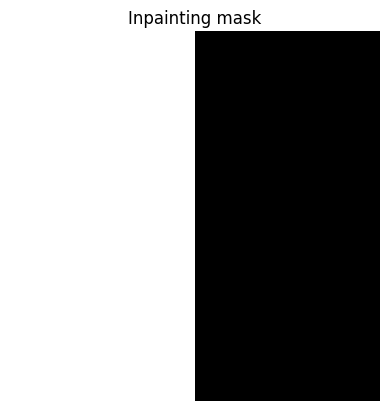

In [4]:
mask= torch.ones(1, image_size, image_size, device=device)
mask[:,:, image_size//2 :] = 0
plt.imshow(mask.squeeze(0).cpu(), cmap="gray")
plt.title("Inpainting mask")
plt.axis("off")
plt.show()

In [5]:
x=x.to(device)
A= dinv.physics.Inpainting(
    mask= mask, img_size= (1,image_size, image_size), device=device,
)
y=A(x)
print("original shape: ", x.shape)
print("masked shape: ", y.shape)

original shape:  torch.Size([64, 1, 32, 32])
masked shape:  torch.Size([64, 1, 32, 32])


In [6]:
def prepare_input(mask, y):
    if mask.dim()==3:
        mask= mask.unsqueeze(0)
    mask_batch=mask.expand_as(y)
    model_input=torch.cat([y,mask_batch], dim=1)
    return model_input, mask_batch

In [7]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv= nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels,kernel_size=3, padding=1),
            nn.ReLU(),
        )
    def forward(self,x):
        return self.conv(x)

In [ ]:
class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.down1= DoubleConv(2,32)
        self.pool1= nn.MaxPool2d(2)
        self.down2= DoubleConv(32,64)
        self.pool2= nn.MaxPool2d(2)

        self.bottleneck= DoubleConv(64,128)

        self.trans2= nn.ConvTranspose2d(128,64,kernel_size=2, stride=2)
        self.up2=DoubleConv(128,64)
        self.trans1=nn.ConvTranspose2d(64,32,kernel_size=2,stride=2)
        self.up1=DoubleConv(64,32)

        self.out=nn.Sequential(
            nn.Conv2d(32,1, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, y, mask):

        model_input, mask_batch= prepare_input(mask,y)

        x1=self.down1(model_input)
        x2=self.pool1(x1)
        x3=self.down2(x2)
        x4=self.pool2(x3)

        x5=self.bottleneck(x4)

        x6=self.trans2(x5)
        x6=torch.cat([x6,x3],dim=1)
        x7=self.up2(x6)
        x8=self.trans1(x7)
        x8=torch.cat([x8,x1], dim =1)
        x9=self.up1(x8)
        predicted_normalized= self.out(x9)
        reconstruction = y*mask_batch + predicted_normalized*(1-mask_batch)

        return reconstruction


In [ ]:
import torch.nn.functional as F
model= UNet().to(device)
optimizer= torch.optim.Adam(model.parameters(), lr=1e-3)
mse= nn.MSELoss(reduction="none")
epochs=40 #20
train_losses=[]
for epoch in range(epochs):
    model.train()
    epoch_loss= 0.0
    for batch in tqdm(train_loader, desc=f"Epoch{epoch+1}/{epochs}"):
        x=batch[0].to(device)
        y=A(x)
        A_inv= model(y,mask)
        if mask.dim()==3:
            mask_for_loss=mask.unsqueeze(0)
        mask_for_loss= mask_for_loss.expand_as(x)
        missing_region= 1-mask_for_loss


        pixel_loss= mse(A_inv, x) #(A_inv - x)**2
        weight= 1.0 +20.0*x
        weighted_missing=missing_region*weight
        loss= (pixel_loss*weighted_missing).sum()/weighted_missing.sum()

        '''
        bce_loss = F.binary_cross_entropy(A_inv, x, reduction="none")
        l1_loss = torch.abs(A_inv - x)

        weight = 1.0 + 50.0 * x
        weighted_missing = missing_region * weight

        loss_bce = (bce_loss * weighted_missing).sum() / weighted_missing.sum()
        loss_l1 = (l1_loss * weighted_missing).sum() / weighted_missing.sum()

        loss = loss_bce + 0.2 * loss_l1
        '''

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss+= loss.item()

    avg_loss=epoch_loss/len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch{epoch+1}/{epoch}-loss, {avg_loss: .6f}")

Epoch1/40:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch1/0-loss,  0.067468


Epoch2/40:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch2/1-loss,  0.045352


Epoch3/40:   0%|          | 0/938 [00:00<?, ?it/s]

...

Epoch38/37-loss,  0.026856


Epoch39/40:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch39/38-loss,  0.026720


Epoch40/40:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch40/39-loss,  0.026533


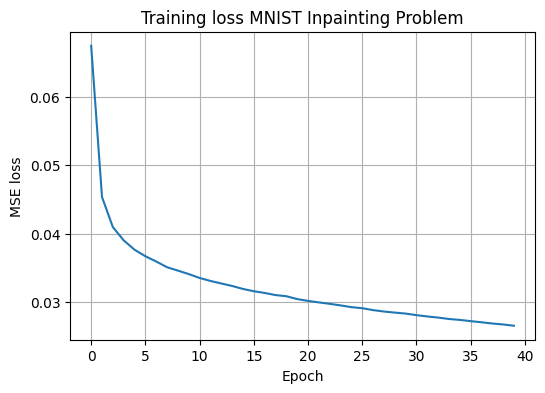

In [51]:
plt.figure(figsize=(6,4))
plt.plot(train_losses)
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training loss MNIST Inpainting Problem")
plt.grid(True)
plt.show()

In [ ]:
model.eval()

with torch.no_grad():
    x_test, _ = next(iter(test_loader))   
    x_test = x_test.to(device)

    y_test = A(x_test)
    A_inv_test = model(y_test, mask)
    if mask.dim() == 3:
        mask_eval = mask.unsqueeze(0)
    else:
        mask_eval = mask

    mask_eval = mask_eval.expand_as(x_test)
    missing_region = 1 - mask_eval

    print("Reconstruction missing mean:",
          (A_inv_test * missing_region).sum().item() / missing_region.sum().item())

    print("Original missing mean:",
          (x_test * missing_region).sum().item() / missing_region.sum().item())

    print("Masked missing mean:",
          (y_test * missing_region).sum().item() / missing_region.sum().item())

Reconstruction missing mean: 0.15885329246520996
Original missing mean: 0.12767943739891052
Masked missing mean: 0.0


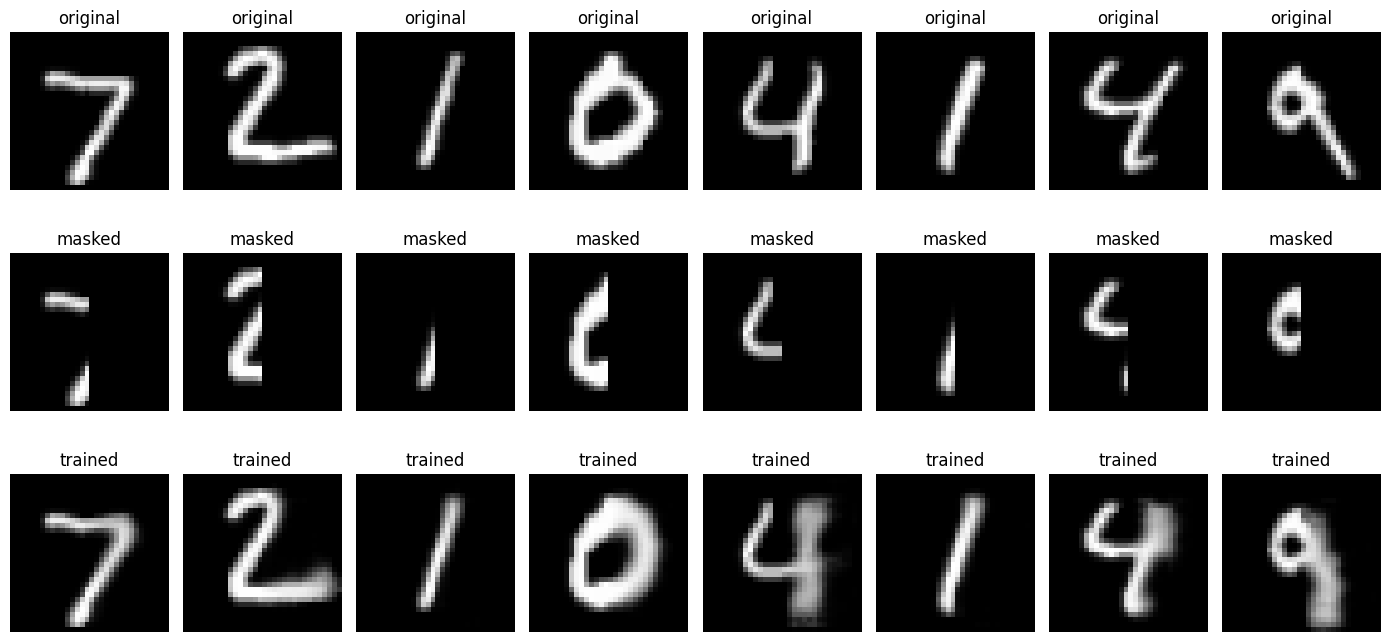

In [12]:
num_images= min(8, x_test.shape[0])
fig, axes= plt.subplots(3, num_images, figsize=(14,7))
for i in range (num_images):
    axes[0,i].imshow(x_test[i,0].detach().cpu(), cmap="gray")
    axes[0,i].axis("off")
    axes[0,i].set_title("original")
    axes[1,i].imshow(y_test[i,0].detach().cpu(), cmap="gray")
    axes[1,i].axis("off")
    axes[1,i].set_title("masked")
    axes[2,i].imshow(A_inv_test[i,0].detach().cpu(), cmap="gray")
    axes[2,i].axis("off")
    axes[2,i].set_title("trained")
plt.tight_layout()
plt.show()


In [55]:
checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)
model_path=checkpoints/"trained_results.pth"
torch.save(model.state_dict(), model_path)
print("saved results to: ", model_path)

saved results to:  checkpoints/trained_results.pth


In [9]:
model_path=Path("trained_results.pth")
model = UNet().to(device)
model.load_state_dict(
    torch.load(model_path, map_location=device)
)
model.eval()
print("model loaded!")

model loaded!


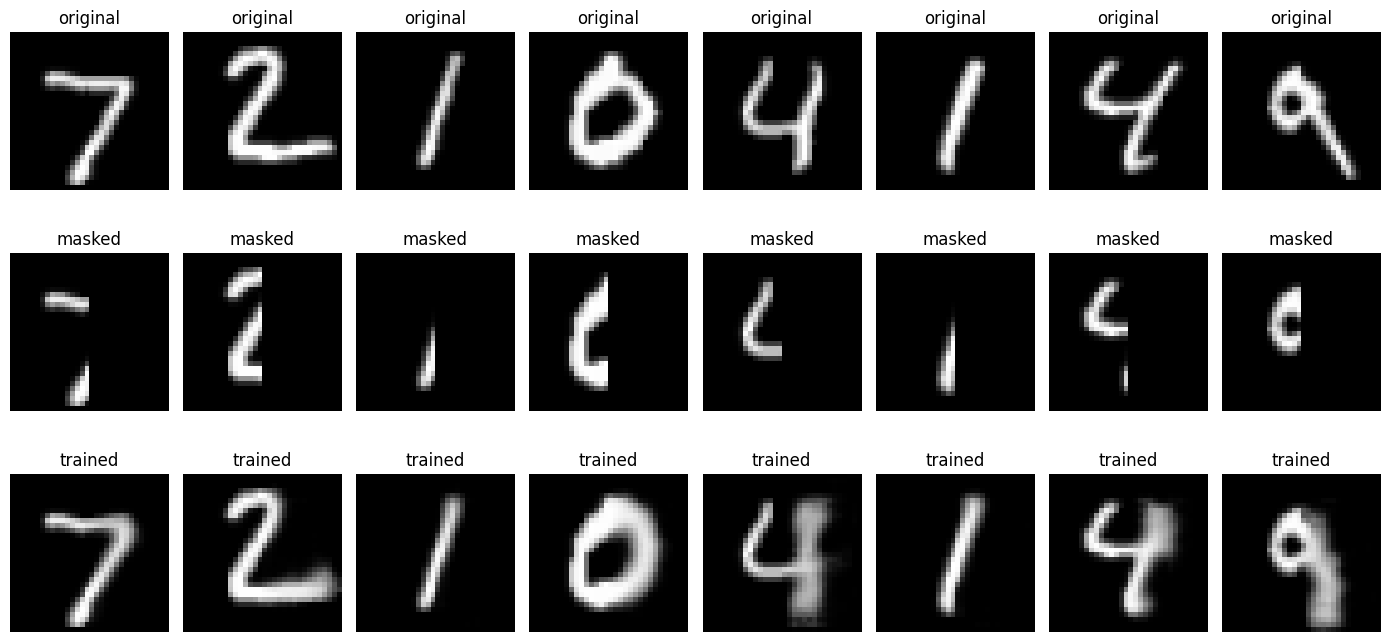

In [20]:
num_images= min(8, x_test.shape[0])
fig, axes= plt.subplots(3, num_images, figsize=(14,7))
for i in range (num_images):
    axes[0,i].imshow(x_test[i,0].detach().cpu(), cmap="gray")
    axes[0,i].axis("off")
    axes[0,i].set_title("original")
    axes[1,i].imshow(y_test[i,0].detach().cpu(), cmap="gray")
    axes[1,i].axis("off")
    axes[1,i].set_title("masked")
    axes[2,i].imshow(A_inv_test[i,0].detach().cpu(), cmap="gray")
    axes[2,i].axis("off")
    axes[2,i].set_title("trained")
plt.tight_layout()
plt.show()


In [5]:
import sys
project_root= Path.cwd().parent
sys.path.append(str(project_root))
import models.unet_with_resblocks as unet_res
import importlib
importlib.reload(unet_res)
from models.unet_with_resblocks import ResBlock


block=ResBlock(128,256)
x=torch.randn(4,128,28,28)
y=block(x)
print(y.shape)

torch.Size([4, 256, 28, 28])


In [6]:
from models.unet_with_resblocks import Downsample

down_conv= Downsample(128)
x=torch.randn(4,128,28,28)
y= down_conv(x)
print(y.shape)


torch.Size([4, 128, 14, 14])


In [7]:
from models.unet_with_resblocks import Upsample
up_conv=Upsample(128)
x=torch.randn(4,128,14,14)
y= up_conv(x)
print(y.shape)

torch.Size([4, 128, 28, 28])


In [7]:
importlib.reload(unet_res)
UNetWithResBlocks= unet_res.UNetRes

In [8]:
model= UNetWithResBlocks(2,1,128,(1,2,4),2,0.1).to(device)

In [9]:
y=torch.rand(4,1,32,32).to(device)
mask= torch.randint(0,2,(1,32,32)).float().to(device)
output= model(y,mask)
print("input shape", y.shape)
print("output shape", output.shape)

input shape torch.Size([4, 1, 32, 32])
output shape torch.Size([4, 1, 32, 32])


In [10]:
num_parameters= sum(p.numel() for p in model.parameters() if p.requires_grad)
print("trainable param:", num_parameters)

trainable param: 19447847


In [ ]:
from utils.masks import random_circle_mask
x_test=x_test.to(device)
masks= random_circle_mask(x_test,min_radius=4.0, max_radius=8.0, min_pixel_value=0.5)
y=x_test*masks

C:\Users\islem\AppData\Roaming\Python\Python312\site-packages\torch\functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4383.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


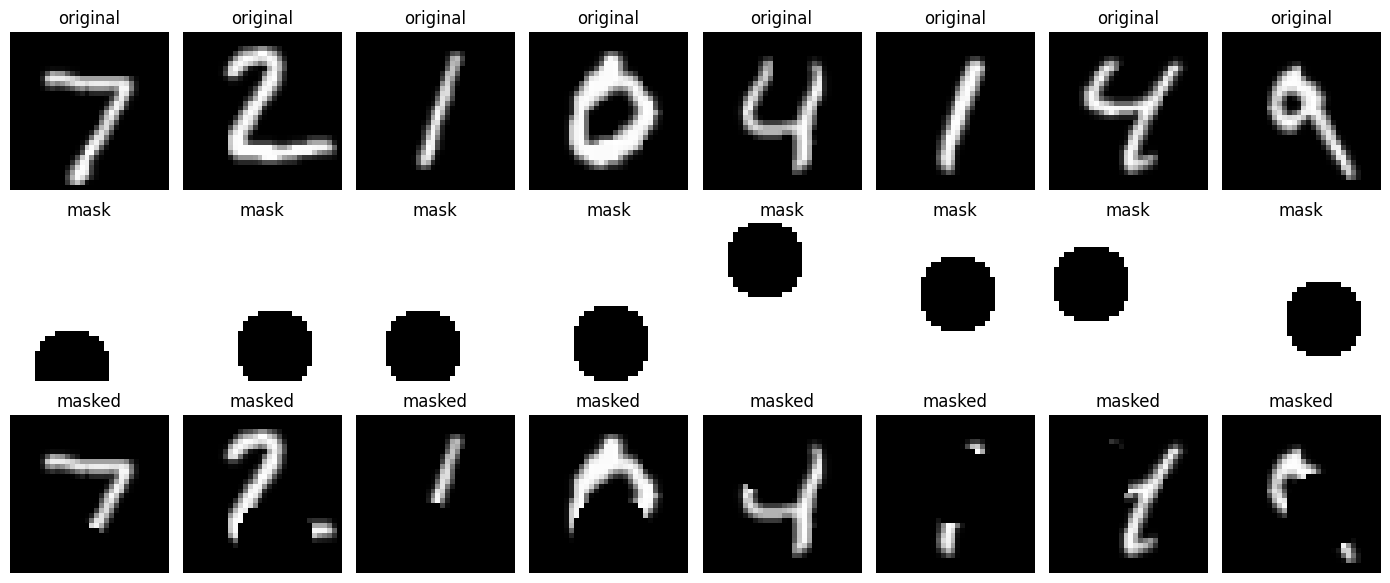

In [9]:
num_images = min(8, x_test.shape[0])

fig, axes = plt.subplots(3, num_images, figsize=(14, 6))

for i in range(num_images):
    axes[0, i].imshow(x_test[i, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[0, i].set_title("original")

    axes[1, i].imshow(masks[i, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].axis("off")
    axes[1, i].set_title("mask")

    axes[2, i].imshow(y[i, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
    axes[2, i].axis("off")
    axes[2, i].set_title("masked")

plt.tight_layout()
plt.show()

In [ ]:
model= model.to(device)
checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)
model2_path=checkpoints/"resunet.pth"

optimizer= torch.optim.Adam(model.parameters(), lr=1e-3)
mse= nn.MSELoss(reduction="none")
epochs=40 #20
train_losses=[]
for epoch in range(epochs):
    model.train()
    epoch_loss= 0.0
    for batch in tqdm(train_loader, desc=f"Epoch{epoch+1}/{epochs}"):
        x=batch[0].to(device)
        masks= random_gaussian_mask(x,min_radius=4.0, max_radius=8.0, min_pixel_value=0.5,
                            factor_min=1.0, factor_max=1.5)
        y=x*masks
        A_inv= model(y,masks)
        missing_region= 1-masks


        pixel_loss= mse(A_inv, x) #(A_inv - x)**2
        weight= 1.0 +20.0*x
        weighted_missing=missing_region*weight
        loss= (pixel_loss*weighted_missing).sum()/weighted_missing.sum()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss+= loss.item()

    avg_loss=epoch_loss/len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch{epoch+1}/{epoch}-loss, {avg_loss: .6f}")
    torch.save({
    "model": model.state_dict(), "optimizer": optimizer.state_dict(),"train_losses":train_losses,
     }, model2_path)

Epoch1/40:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch1/0-loss,  0.082563


Epoch2/40:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch2/1-loss,  0.052656


Epoch3/40:   0%|          | 0/938 [00:00<?, ?it/s]

...

Epoch36/40:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch36/35-loss,  0.001950


Epoch37/40:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch37/36-loss,  0.000679


Epoch38/40:   0%|          | 0/938 [00:00<?, ?it/s]

In [ ]:
from pathlib import Path
import torch
checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)
model2_path=checkpoints/"resunet.pth"
torch.save({
    "model": model.state_dict(), "optimizer": optimizer.state_dict(),"train_losses":train_losses,
}, model2_path)
print("saved results to: ", model2_path)

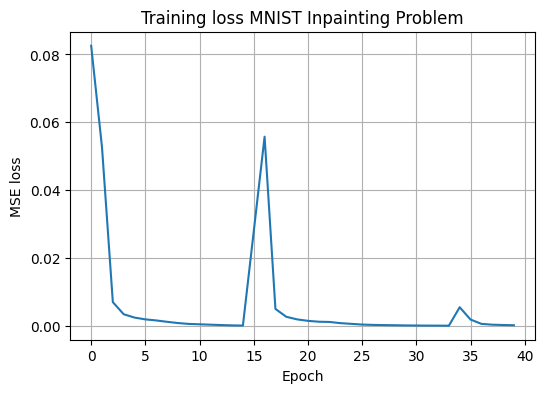

saved to: /home/islem.dhouioui/ddpm/outputs/training_loss_resunet.png


<Figure size 640x480 with 0 Axes>

In [6]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
checkpoints_path= Path("checkpoints/resunet.pth")
checkpoint = torch.load(checkpoints_path,map_location="cpu")
train_losses=checkpoint["train_losses"]
plt.figure(figsize=(6,4))
plt.plot(train_losses)
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training loss MNIST Inpainting Problem")
plt.grid(True)
plt.show()
project_root=Path.cwd().parent if Path.cwd().name=="notebooks" else Path.cwd()
output_path=project_root/"outputs"/"training_loss_resunet.png"
output_path.parent.mkdir(exist_ok=True)
plt.savefig("training_loss_resunet.png")
print("saved to:", output_path)

In [10]:
from models.unet_with_resblocks import UNetRes
from utils.masks import random_gaussian_mask 
model = UNetRes(2,1,128,(1,2,4),2,0.1).to(device)
model.load_state_dict(checkpoint["model"])
model.eval()
print("loaded")

loaded


In [22]:
model.eval()

with torch.no_grad():
    x_test, _ = next(iter(test_loader))   
    x_test = x_test.to(device)
    num_img= min(8, x_test.shape[0])
    x1=x_test[:num_img]
    masks= random_gaussian_mask(x1,min_radius=4.0, max_radius=8.0, min_pixel_value=0.5,
                            factor_min=1.5, factor_max=2.5)
    y1=x1*masks
    reconstructed= model(y1,masks)

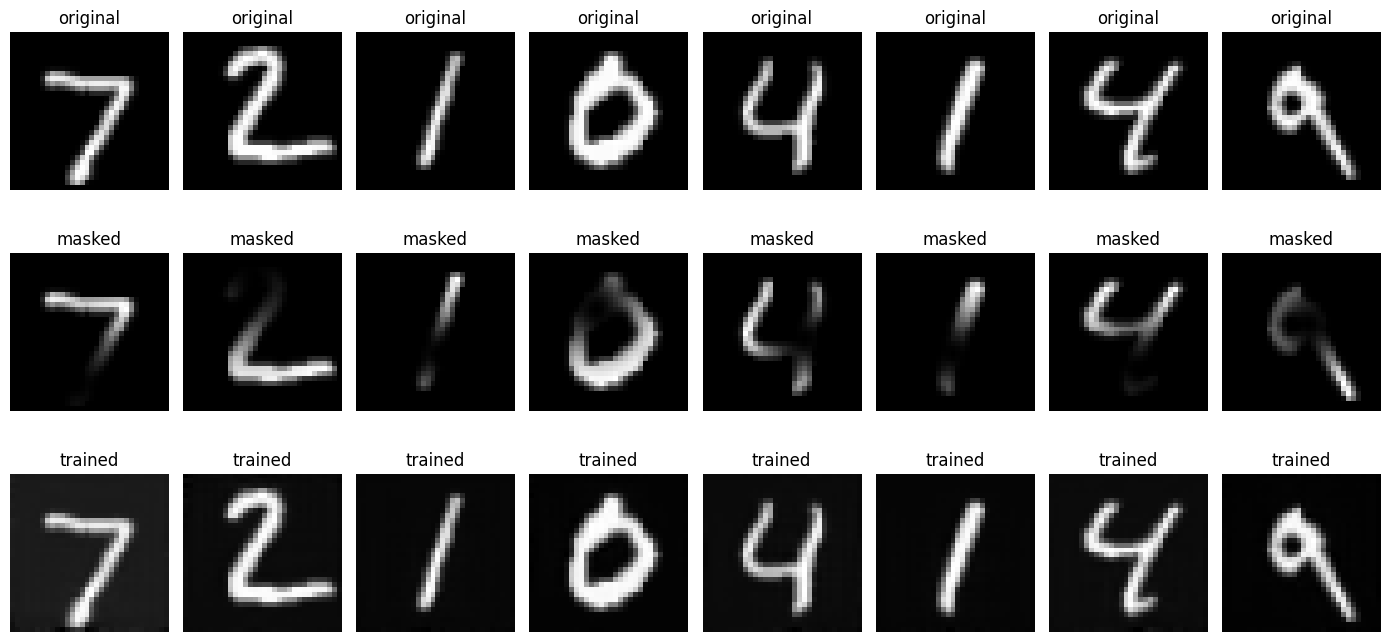

In [23]:
fig, axes= plt.subplots(3, num_img, figsize=(14,7))
for i in range (num_img):
    axes[0,i].imshow(x1[i,0].detach().cpu(), cmap="gray")
    axes[0,i].axis("off")
    axes[0,i].set_title("original")
    axes[1,i].imshow(y1[i,0].detach().cpu(), cmap="gray")
    axes[1,i].axis("off")
    axes[1,i].set_title("masked")
    axes[2,i].imshow(reconstructed[i,0].detach().cpu(), cmap="gray")
    axes[2,i].axis("off")
    axes[2,i].set_title("trained")
plt.tight_layout()
plt.show()